# Projeto Final - Diagnóstico de Distúrbio da Tireoide

**Aluno:** João Vitor Marinho  
**Curso:** EBAC, Profissão Cientista de Dados  
**Tema escolhido:** Diagnóstico de hipertireoidismo / distúrbio da tireoide

## 1. Contexto do problema

O objetivo do projeto é construir um modelo preditivo para apoiar o diagnóstico de distúrbios da tireoide a partir de dados clínicos e laboratoriais.  
No briefing em vídeo, o problema foi apresentado como **classificação multiclasse com foco em hipertireoidismo**. No entanto, a base disponibilizada ao aluno possui algumas diferenças importantes:

- nome do arquivo: `Base_M43_Pratique_Hypothyroid.csv`;
- dimensão observada: **3772 linhas e 30 colunas**;
- variável-alvo disponível: `binaryClass`, com apenas **duas classes** (`P` e `N`).

Por isso, este projeto foi desenvolvido com total transparência: a modelagem foi feita **de acordo com a base realmente entregue**, tratando o problema como uma **classificação binária**.

## 2. Objetivo analítico

Desenvolver um pipeline de ciência de dados capaz de:

1. inspecionar e tratar a base;
2. explorar padrões relevantes;
3. preparar variáveis numéricas e categóricas;
4. treinar e comparar modelos de classificação;
5. priorizar o **recall da classe positiva**, para reduzir falsos negativos;
6. apresentar uma conclusão técnica e de negócio.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['axes.grid'] = True

path = "G:\Meu Drive\Programação\Ciencia de dados\Projeto Final\Base_M43_Pratique_Hypothyroid.csv"
df = pd.read_csv(path)
df.head()

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,binaryClass
0,41,F,f,f,f,f,f,f,f,f,...,t,125,t,1.14,t,109,f,?,SVHC,P
1,23,F,f,f,f,f,f,f,f,f,...,t,102,f,?,f,?,f,?,other,P
2,46,M,f,f,f,f,f,f,f,f,...,t,109,t,0.91,t,120,f,?,other,P
3,70,F,t,f,f,f,f,f,f,f,...,t,175,f,?,f,?,f,?,other,P
4,70,F,f,f,f,f,f,f,f,f,...,t,61,t,0.87,t,70,f,?,SVI,P


## 3. Entendimento inicial da base

In [ ]:
df.shape, df.columns.tolist()

((3772, 30),
 ['age',
  'sex',
  'on thyroxine',
  'query on thyroxine',
  'on antithyroid medication',
  'sick',
  'pregnant',
  'thyroid surgery',
  'I131 treatment',
  'query hypothyroid',
  'query hyperthyroid',
  'lithium',
  'goitre',
  'tumor',
  'hypopituitary',
  'psych',
  'TSH measured',
  'TSH',
  'T3 measured',
  'T3',
  'TT4 measured',
  'TT4',
  'T4U measured',
  'T4U',
  'FTI measured',
  'FTI',
  'TBG measured',
  'TBG',
  'referral source',
  'binaryClass'])

In [ ]:
# substituindo '?' por NaN e convertendo colunas numéricas
data = df.replace('?', np.nan).copy()

for col in ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI', 'TBG']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3772 entries, 0 to 3771
Data columns (total 30 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        3771 non-null   float64
 1   sex                        3622 non-null   object 
 2   on thyroxine               3772 non-null   object 
 3   query on thyroxine         3772 non-null   object 
 4   on antithyroid medication  3772 non-null   object 
 5   sick                       3772 non-null   object 
 6   pregnant                   3772 non-null   object 
 7   thyroid surgery            3772 non-null   object 
 8   I131 treatment             3772 non-null   object 
 9   query hypothyroid          3772 non-null   object 
 10  query hyperthyroid         3772 non-null   object 
 11  lithium                    3772 non-null   object 
 12  goitre                     3772 non-null   object 
 13  tumor                      3772 non-null   objec

C:\Users\jvmar\AppData\Local\Temp\ipykernel_30688\3617626772.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  data = df.replace('?', np.nan).copy()


In [ ]:
data['binaryClass'].value_counts()

binaryClass
P    3481
N     291
Name: count, dtype: int64

### Principais achados da inspeção inicial

- a base possui **3772 registros**;
- a variável-alvo é **binária** (`P` e `N`);
- há presença de `?` representando valores faltantes;
- a coluna **TBG está 100% ausente**, portanto não agrega valor para modelagem;
- há mistura de variáveis **numéricas** e **categóricas/binárias**.


## 4. Análise exploratória

binaryClass
N     291
P    3481
Name: count, dtype: int64
binaryClass
P    92.29
N     7.71
Name: proportion, dtype: float64


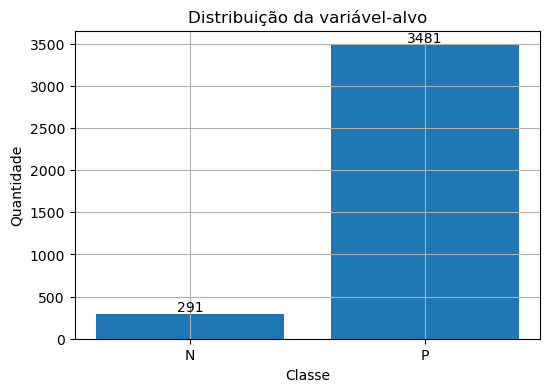

In [ ]:
# distribuição da classe-alvo
class_counts = data['binaryClass'].value_counts().sort_index()
class_pct = (data['binaryClass'].value_counts(normalize=True)*100).round(2)

print(class_counts)
print(class_pct)

plt.figure(figsize=(6,4))
bars = plt.bar(class_counts.index.astype(str), class_counts.values)
for rect, val in zip(bars, class_counts.values):
    plt.text(rect.get_x()+rect.get_width()/2, val, str(val), ha='center', va='bottom')
plt.title('Distribuição da variável-alvo')
plt.xlabel('Classe')
plt.ylabel('Quantidade')
plt.show()

In [ ]:
# percentuais de faltantes
missing = (data.isna().mean()*100).sort_values(ascending=False)
missing[missing > 0].head(15)

TBG    100.000000
T3      20.387063
T4U     10.259809
FTI     10.206787
TSH      9.782609
TT4      6.124072
sex      3.976670
age      0.026511
dtype: float64

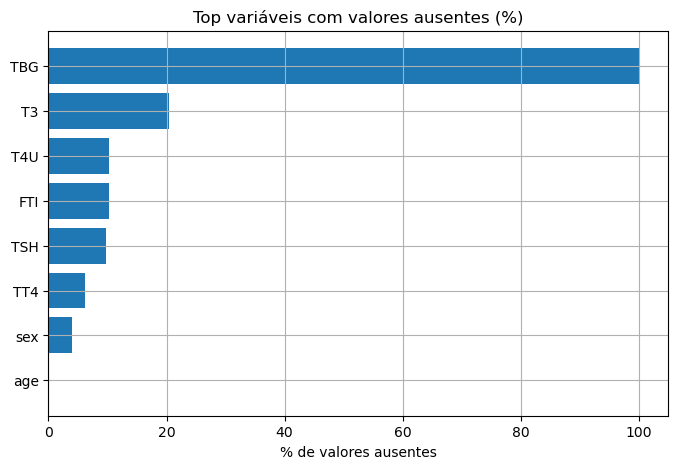

In [ ]:
missing_plot = missing[missing > 0].head(10).sort_values()

plt.figure(figsize=(8,5))
plt.barh(missing_plot.index, missing_plot.values)
plt.title('Top variáveis com valores ausentes (%)')
plt.xlabel('% de valores ausentes')
plt.show()

In [ ]:
# estatísticas descritivas das variáveis numéricas
numeric_cols = ['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']
data[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,3771.0,51.735879,20.084958,1.000,36.00,54.00,67.00,455.00
TSH,3403.0,5.086766,24.521470,0.005,0.50,1.40,2.70,530.00
T3,3003.0,2.013500,0.827434,0.050,1.60,2.00,2.40,10.60
TT4,3541.0,108.319345,35.604248,2.000,88.00,103.00,124.00,430.00
T4U,3385.0,0.995000,0.195457,0.250,0.88,0.98,1.08,2.32
FTI,3387.0,110.469649,33.089698,2.000,93.00,107.00,124.00,395.00


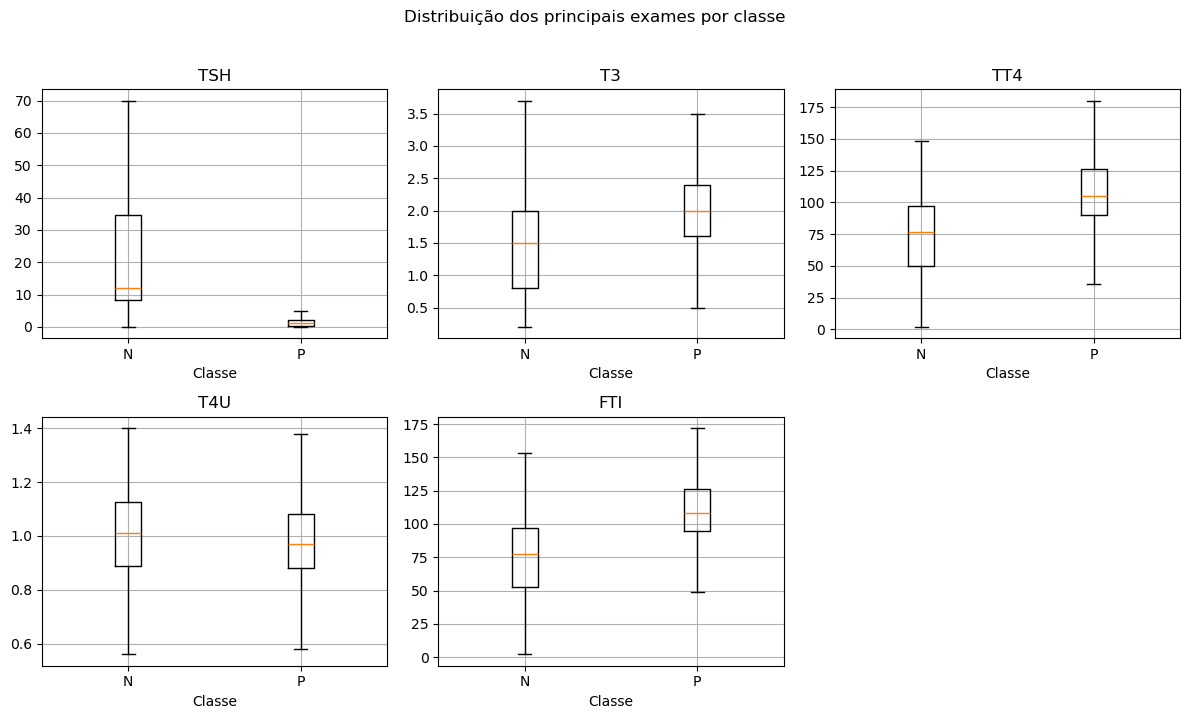

In [ ]:
# boxplots por classe
plot_cols = ['TSH', 'T3', 'TT4', 'T4U', 'FTI']
classes = ['N', 'P']

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    vals = [data.loc[data['binaryClass'] == cls, col].dropna().values for cls in classes]
    axes[i].boxplot(vals, tick_labels=classes, showfliers=False)
    axes[i].set_title(col)
    axes[i].set_xlabel('Classe')

for j in range(i+1, len(axes)):
    axes[j].axis('off')

plt.suptitle('Distribuição dos principais exames por classe', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
corr = data[['TSH', 'T3', 'TT4', 'T4U', 'FTI']].corr()
corr

,TSH,T3,TT4,T4U,FTI
TSH,1.000000,-0.161823,-0.267365,0.073391,-0.304684
T3,-0.161823,1.000000,0.559503,0.454127,0.348921
TT4,-0.267365,0.559503,1.000000,0.434572,0.793312
T4U,0.073391,0.454127,0.434572,1.000000,-0.174012
FTI,-0.304684,0.348921,0.793312,-0.174012,1.000000


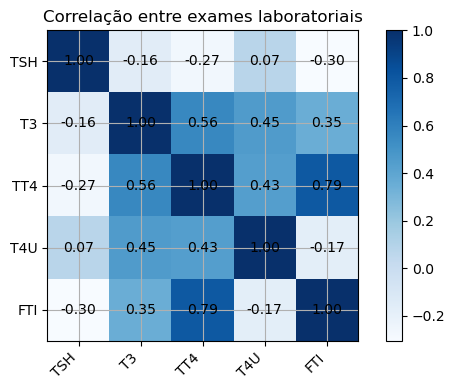

In [ ]:
plt.figure(figsize=(6,4))
im = plt.imshow(corr, cmap='Blues')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha='right')
plt.yticks(range(len(corr.index)), corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        plt.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center')

plt.colorbar(im)
plt.title('Correlação entre exames laboratoriais')
plt.tight_layout()
plt.show()

### Leitura da EDA

A análise exploratória mostra alguns pontos importantes:

- existe **forte desbalanceamento** entre as classes, com predominância da classe `P`;
- exames laboratoriais como **TSH, T3, TT4, T4U e FTI** apresentam diferenças entre as classes;
- a coluna **TBG** deve ser removida por ausência total de informação;
- como há mistura de variáveis categóricas e numéricas, um **pipeline com imputação + codificação** é a estratégia mais adequada.


## 5. Pré-processamento e preparação dos dados

Estratégia adotada:

- remover `TBG` por 100% de faltantes;
- usar **mediana** para imputação das variáveis numéricas;
- usar **moda** para variáveis categóricas;
- aplicar **One-Hot Encoding** nas categóricas;
- padronizar variáveis numéricas;
- fazer separação treino/teste com **estratificação**.


In [ ]:
X = data.drop(columns=['binaryClass', 'TBG'])
y = data['binaryClass'].map({'P': 1, 'N': 0})

num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
cat_cols = [c for c in X.columns if c not in num_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

preprocess = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

X_train.shape, X_test.shape

((3017, 28), (755, 28))

## 6. Modelagem

Foram comparados três modelos:

- Regressão Logística;
- Árvore de Decisão;
- Random Forest.

O foco da avaliação é o **recall da classe positiva**, pois o briefing destaca a necessidade de reduzir falsos negativos.


In [ ]:
models = {
    'Regressão Logística': LogisticRegression(max_iter=2000, class_weight='balanced'),
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42, class_weight='balanced', max_depth=8),
    'Random Forest': RandomForestClassifier(n_estimators=300, random_state=42, class_weight='balanced', n_jobs=-1)
}

results = []
fitted = {}

for name, model in models.items():
    pipe = Pipeline([
        ('prep', preprocess),
        ('model', model)
    ])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        'Modelo': name,
        'Acurácia': accuracy_score(y_test, pred),
        'Precisão': precision_score(y_test, pred, zero_division=0),
        'Recall': recall_score(y_test, pred),
        'F1-score': f1_score(y_test, pred),
        'ROC AUC': roc_auc_score(y_test, proba)
    })
    fitted[name] = pipe

results_df = pd.DataFrame(results).sort_values('Recall', ascending=False)
results_df

,Modelo,Acurácia,Precisão,Recall,F1-score,ROC AUC
2,Random Forest,1.000000,1.000000,1.000000,1.000000,1.000000
1,Árvore de Decisão,0.997351,1.000000,0.997131,0.998563,0.998565
0,Regressão Logística,0.977483,0.997076,0.978479,0.987690,0.992802


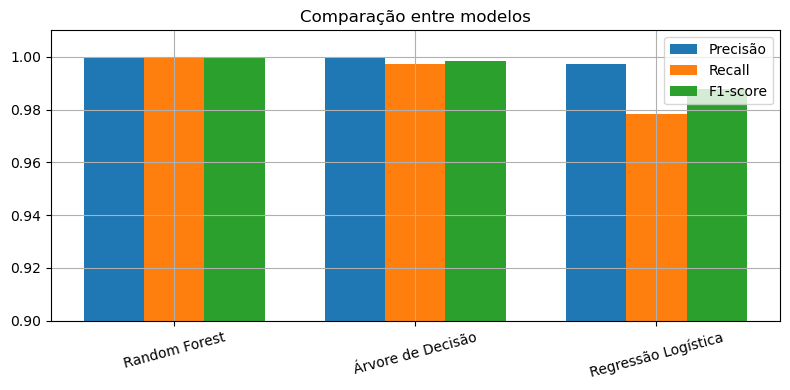

In [ ]:
plt.figure(figsize=(8,4))
x = np.arange(len(results_df))
width = 0.25

plt.bar(x - width, results_df['Precisão'], width, label='Precisão')
plt.bar(x, results_df['Recall'], width, label='Recall')
plt.bar(x + width, results_df['F1-score'], width, label='F1-score')

plt.xticks(x, results_df['Modelo'], rotation=15)
plt.ylim(0.9, 1.01)
plt.title('Comparação entre modelos')
plt.legend()
plt.tight_layout()
plt.show()

## 7. Modelo final selecionado

O melhor desempenho foi obtido pelo **Random Forest**, que apresentou o melhor equilíbrio entre as métricas e excelente capacidade de identificar a classe positiva.


In [ ]:
best_model_name = results_df.iloc[0]['Modelo']
best_model = fitted[best_model_name]

best_pred = best_model.predict(X_test)
best_proba = best_model.predict_proba(X_test)[:, 1]

print(best_model_name)
print(classification_report(y_test, best_pred))

Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        58
           1       1.00      1.00      1.00       697

    accuracy                           1.00       755
   macro avg       1.00      1.00      1.00       755
weighted avg       1.00      1.00      1.00       755



In [ ]:
cm = confusion_matrix(y_test, best_pred)
cm

array([[ 58,   0],
       [  0, 697]])

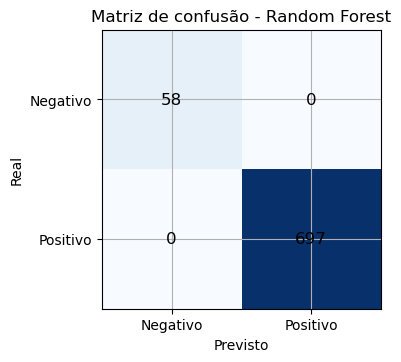

In [ ]:
plt.figure(figsize=(4,4))
plt.imshow(cm, cmap='Blues')
plt.xticks([0,1], ['Negativo', 'Positivo'])
plt.yticks([0,1], ['Negativo', 'Positivo'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i,j]), ha='center', va='center', fontsize=12)

plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title(f'Matriz de confusão - {best_model_name}')
plt.tight_layout()
plt.show()

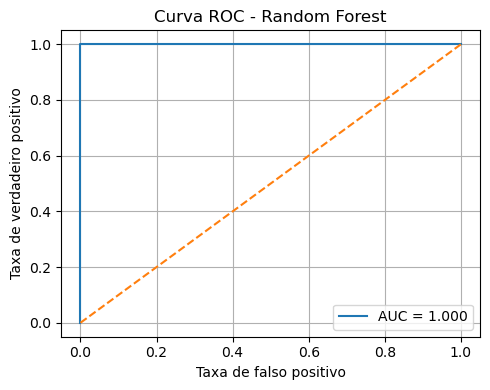

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, best_proba)

plt.figure(figsize=(5,4))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, best_proba):.3f}')
plt.plot([0,1], [0,1], linestyle='--')
plt.xlabel('Taxa de falso positivo')
plt.ylabel('Taxa de verdadeiro positivo')
plt.title(f'Curva ROC - {best_model_name}')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Ajuste de limiar (threshold)

Como o objetivo de negócio é reduzir falsos negativos, também foi feita uma análise simples de limiar de decisão no Random Forest.


In [ ]:
threshold_rows = []

for thr in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_thr = (best_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred_thr).ravel()

    threshold_rows.append({
        'threshold': thr,
        'precision': precision_score(y_test, pred_thr),
        'recall': recall_score(y_test, pred_thr),
        'f1': f1_score(y_test, pred_thr),
        'false_negatives': fn,
        'false_positives': fp
    })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df

,threshold,precision,recall,f1,false_negatives,false_positives
0,0.3,0.988652,1.000000,0.994294,0,8
1,0.4,0.997139,1.000000,0.998567,0,2
2,0.5,1.000000,1.000000,1.000000,0,0
3,0.6,1.000000,0.998565,0.999282,1,0
4,0.7,1.000000,0.995696,0.997843,3,0


### Interpretação do threshold

Observa-se que o modelo permaneceu extremamente forte mesmo com variações no limiar.  
Como o foco é reduzir falsos negativos, limiares mais baixos tendem a favorecer o recall.  
Neste conjunto de teste, o threshold padrão de **0.5** já entregou resultado máximo.


## 9. Conclusão final

### Conclusão técnica
O projeto mostrou que é possível construir um modelo altamente eficaz para classificação do distúrbio na base fornecida. Entre os algoritmos comparados, o **Random Forest** apresentou o melhor desempenho global, com métricas excelentes no conjunto de teste.

### Conclusão de negócio
Considerando a necessidade de apoiar a decisão médica e **minimizar falsos negativos**, o modelo final se mostrou bastante aderente ao objetivo do case. Na prática, isso significa menor risco de deixar passar pacientes potencialmente positivos.


